In [4]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def plot_alternating_optimization_history(
    csv_path='sre_logspace_history.csv',
    max_epoch=None,
    label=None,
    left_ylim=None,
    left_ylabel=None,
    save_path=None
):
    """
    Plot the alternating optimization history of OnlineDeepLnSRESolver (log-space).
    Strictly preserves the two-panel subplot layout.
    """
    try:
        df = pd.read_csv(csv_path)
    except FileNotFoundError:
        print(f"[Error] File not found: {csv_path}")
        return

    if label is None:
        label = os.path.splitext(os.path.basename(csv_path))[0].replace('_', ' ')

    # Check required columns
    required = ['epoch', 'loss', 'yt_mean', 'yt_std', 'p0', 'freeze_p0', 'freeze_lambda']
    missing = [c for c in required if c not in df.columns]
    if missing:
        print(f"[Warning] CSV is missing required columns {missing}.")
        return

    if max_epoch is not None:
        df = df[df['epoch'] <= max_epoch].copy()

    epochs = df['epoch']
    yt_mean = df['yt_mean']
    yt_std = df['yt_std']
    loss = df['loss']
    p0 = df['p0']
    freeze_p0 = df['freeze_p0']
    freeze_lambda = df['freeze_lambda']

    # ==================== Extract Training Phases ====================
    def get_state(p_flag, l_flag):
        if p_flag and not l_flag:
            return 'Fix_P0'
        elif not p_flag and l_flag:
            return 'Fix_Lambda'
        return 'Joint'

    phases = []
    if len(df) > 0:
        current_state = get_state(freeze_p0.iloc[0], freeze_lambda.iloc[0])
        start_epoch = epochs.iloc[0]
        for i in range(1, len(df)):
            state = get_state(freeze_p0.iloc[i], freeze_lambda.iloc[i])
            if state != current_state:
                phases.append((current_state, start_epoch, epochs.iloc[i - 1]))
                current_state = state
                start_epoch = epochs.iloc[i]
        phases.append((current_state, start_epoch, epochs.iloc[-1]))

    # ==================== Plot Two-Panel Figure ====================
    fig, (ax1, ax2) = plt.subplots(
        2, 1, figsize=(14, 10), sharex=True,
        gridspec_kw={'height_ratios': [1.5, 1]}
    )

    # ---------- Panel A (Top): Terminal State + P0 Trajectory ----------
    ax1_twin = ax1.twinx()

    # Terminal distribution in log-space
    ax1.plot(epochs, yt_mean, label=r'$\mathbb{E}[\tilde{P}_T]$ (Mean)', color='#1f77b4', linewidth=2)
    ax1.fill_between(
        epochs, yt_mean - yt_std, yt_mean + yt_std,
        color='#1f77b4', alpha=0.2, label=r'$\pm 1$ Std Dev'
    )
    ax1.axhline(y=0.0, color='red', linestyle='--', linewidth=1.8, label=r'Target: $\tilde{P}(T) = 0$')

    # Initial value P0 trajectory (right y-axis)
    ax1_twin.plot(epochs, p0, label=r'$\tilde{P}(0)$ Trajectory', color='#2ca02c', linewidth=2.5)

    # Custom left y-axis label and limits
    if left_ylabel is None:
        left_ylabel = r'Terminal State $\tilde{P}_T$ (Log Space)'
    ax1.set_ylabel(left_ylabel, fontsize=12, color='#1f77b4')

    if left_ylim is not None:
        ax1.set_ylim(left_ylim)
        print(f"[Info] Left y-axis limits set to: {left_ylim}")

    ax1_twin.set_ylabel(r'Initial Value $\tilde{P}(0)$', fontsize=12, color='#2ca02c')
    ax1.tick_params(axis='y', labelcolor='#1f77b4')
    ax1_twin.tick_params(axis='y', labelcolor='#2ca02c')

    lines_1, labels_1 = ax1.get_legend_handles_labels()
    lines_2, labels_2 = ax1_twin.get_legend_handles_labels()
    ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper right', fontsize=11, framealpha=0.9)
    ax1.grid(True, linestyle=':', alpha=0.7)

    # ---------- Panel B (Bottom): Training Loss Curve ----------
    ax2.plot(epochs, loss, label='Training Loss (Mean² + Var)', color='#d62728', linewidth=2)
    ax2.set_yscale('log')
    ax2.set_xlabel('Epoch', fontsize=12)
    ax2.set_ylabel('Loss (Log Scale)', fontsize=12)
    ax2.legend(loc='upper right', fontsize=11, framealpha=0.9)
    ax2.grid(True, linestyle=':', alpha=0.7, which='both')

    # ==================== Global Phase Background Bands ====================
    colors = {
        'Fix_P0': '#1f77b4',
        'Fix_Lambda': '#ff7f0e',
        'Joint': '#2ca02c'
    }
    for ax in [ax1, ax2]:
        for state, start, end in phases:
            ax.axvspan(start, end, color=colors[state], alpha=0.08)

    # Phase legend banner
    ax2.text(
        0.01, 1.04,
        "Background: Blue = Train $\\tilde{\\Lambda}$ (Fix $\\tilde{P}_0$)  |  "
        "Orange = Train $\\tilde{P}_0$ (Fix $\\tilde{\\Lambda}$)  |  "
        "Green = Joint Optimization",
        transform=ax2.transAxes, fontsize=10.5, verticalalignment='bottom',
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.92, edgecolor='gray')
    )

    fig.tight_layout()
    if save_path is not None:
        fig.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()
    plt.close(fig)

[Info] Left y-axis limits set to: (-0.3, 0.3)


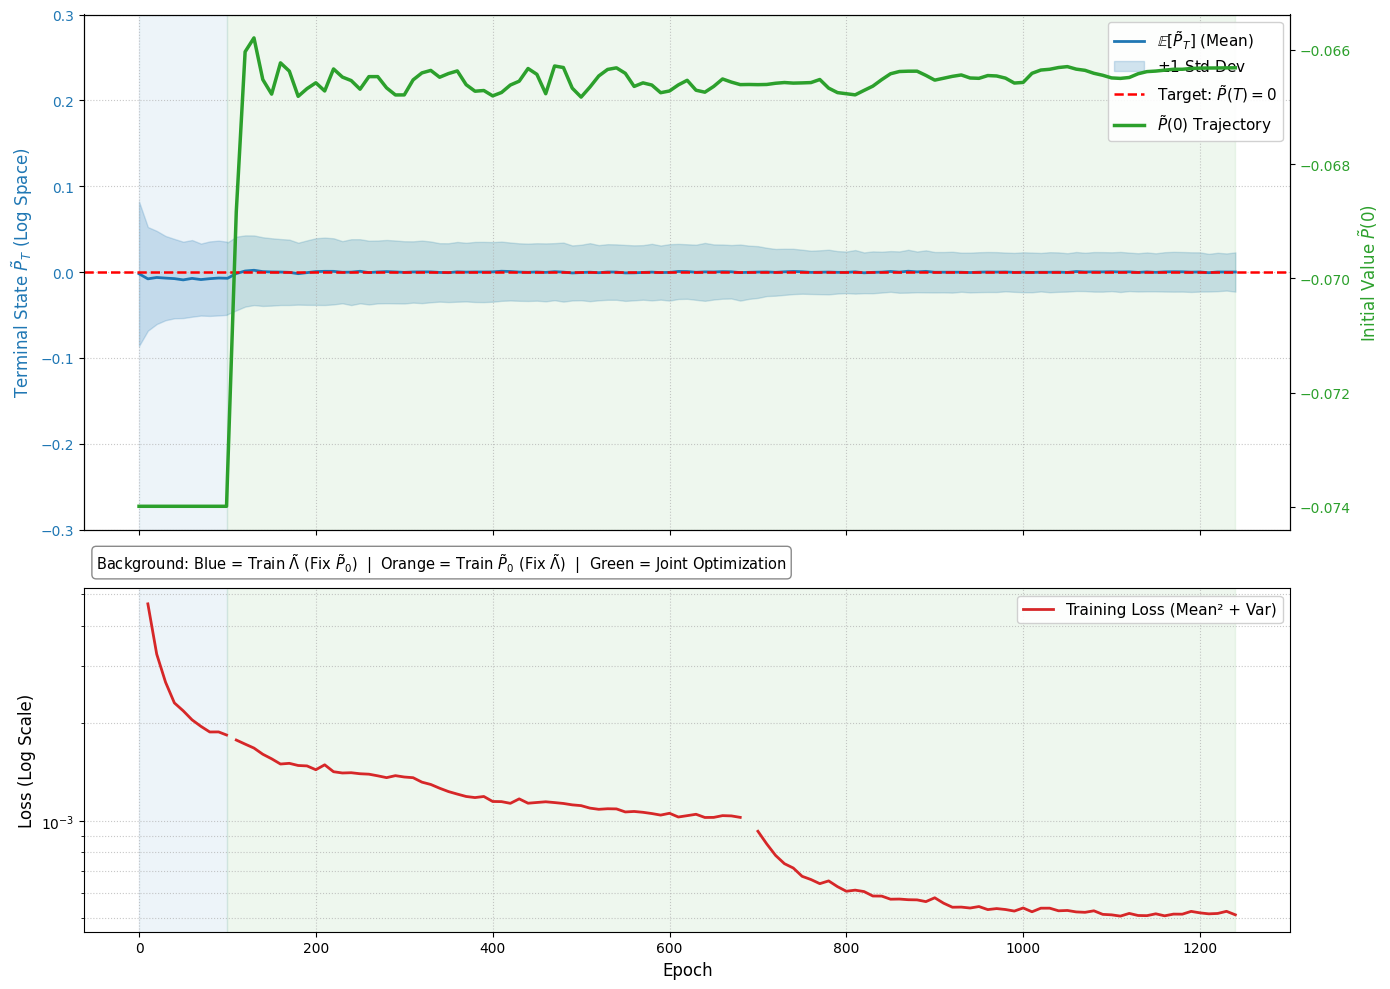

In [5]:
plot_alternating_optimization_history(
    csv_path='OU_P_plus.csv',
    left_ylim=(-0.3, 0.3),          
)

[Info] Left y-axis limits set to: (-0.3, 0.3)


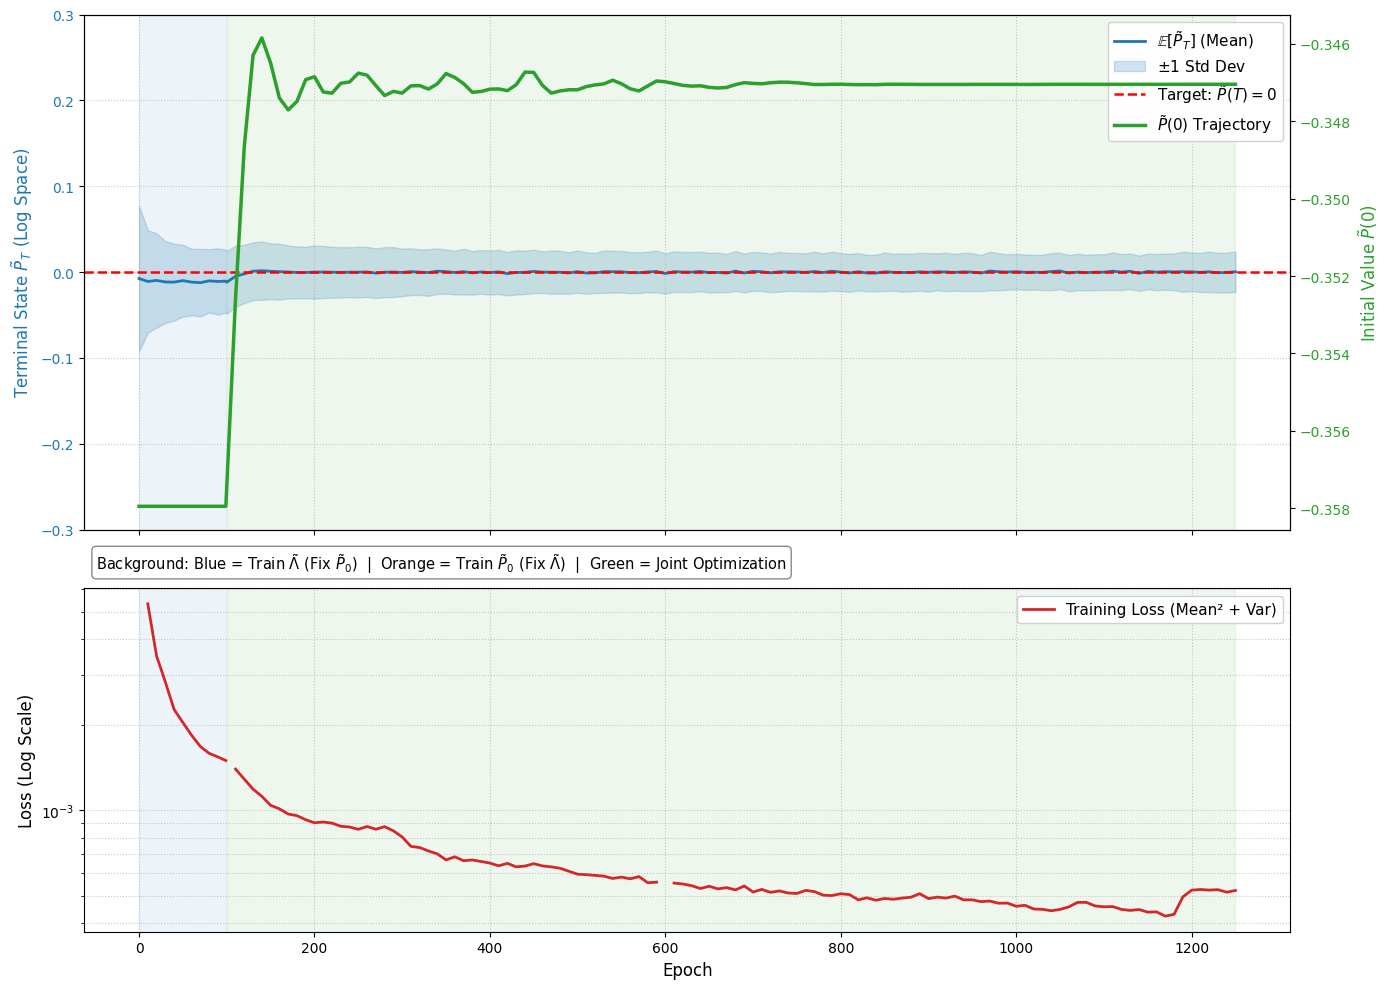

In [6]:
plot_alternating_optimization_history(
    csv_path='OU_P_minus.csv',
    left_ylim=(-0.3, 0.3),          
)